# FER2013 — MLP: Cross-Entropy vs Focal Loss

**Scope:** MLP only. Compare the original Cross-Entropy result with a fresh Cross-Entropy rerun and Focal Loss at gamma = 1, 2 and 4. The same shared `FocalLoss` function is used for the Small CNN and MLP experiments. All runs use the same dataset audit, training/validation split, MLP architecture, optimizer, learning rate, batch size, epoch limit, patience and seed (42). Each run starts from fresh randomly initialized weights.

The source-test split is kept separate and is not used for model selection. All comparisons are validation results.

The last cells combine the MLP results with the Small CNN focal-loss results into one table.


## Run order

Run all cells from top to bottom in Google Colab (GPU if available). The dataset cell downloads FER2013 through KaggleHub. Use the same runtime/device for all experiments; training times are only comparable on the same hardware.

The saved original MLP Cross-Entropy result is kept as a historical reference. The fresh Cross-Entropy rerun is the paired control for the focal-loss runs.


## Packages

Install missing packages, then import the libraries and check the device. The install cell keeps the runtime's existing PyTorch and torchvision versions. `cuda_available` reports NVIDIA CUDA support; the selected device can also be MPS or CPU.


In [ ]:
import importlib.util
import subprocess
import sys

required_packages = {
    "kagglehub": "kagglehub",
    "numpy": "numpy",
    "PIL": "Pillow",
    "matplotlib": "matplotlib",
}
missing_packages = [
    package for module, package in required_packages.items()
    if importlib.util.find_spec(module) is None
]
if missing_packages:
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-q", *missing_packages]
    )
print("Missing lightweight packages installed:", missing_packages or "none")

Missing lightweight packages installed: none


## Shared training settings

These are FT11's documented starting settings. The baseline architectures and the shared Adam/learning-rate/batch settings are unchanged. The custom MLP and small CNN have no universal official default.

`MAX_EPOCHS = 20` caps the passes through all training images. `PATIENCE = 3` stops a run after three epochs without a higher validation macro-F1; lower validation loss breaks an exact F1 tie. The selected checkpoint can be earlier than the final epoch.

Figure 4 and the paper text specify two dropout layers at 0.2. That fixed architecture choice belongs to the Paper-based CNN. The paper reports batch size 512 and 10 epochs, but does not identify its optimizer, learning rate, initialization scheme, or random seed. For this comparison, the Paper-based CNN uses the same FT11 optimizer, batch size, budget, and stopping rule as the baselines. It does not claim the paper's reported score.

Report use: Solutions, evaluation, and discussions / methods and training setup.


In [ ]:
from pathlib import Path

SEED = 42                       # Repeat initialization and batch order for this experiment
VALIDATION_FRACTION = 0.15
EXPERIMENT_NAME = "mlp-focal-loss"
OPTIMIZER_NAME = "Adam"          # "Adam" or "SGD"
MOMENTUM = 0.9                   # Used by SGD
LEARNING_RATE = 0.001           # Adam step-size setting shared by the four models
WEIGHT_DECAY = 0.0
BATCH_SIZE = 64                 # Images per weight update; the final batch can be smaller
MAX_EPOCHS = 20                 # Maximum full passes through the training split
PATIENCE = 3                    # Consecutive epochs without a better validation checkpoint
RUN_FINAL_TEST = False           # Use only after model and setting decisions are fixed

DATASET_HANDLE = "msambare/fer2013"
EXPECTED_V1_DATA_FINGERPRINT = "d67be25b0158b2017c0f4ad4eca68b8632bd9ec66bb579cf2de8224fe1eabf82"
OUTPUT_BASE = Path("/content/fer2013_colab_runs" if Path("/content").is_dir() else "fer2013_colab_runs")
NOTEBOOK_FILE = "MLP_FocalLoss_Experiments.ipynb"
NOTEBOOK_REVISION = "mlp-focal-loss-v1"
NOTEBOOK_TEMPLATE_SOURCE_SHA256 = "mlp-focal-loss-copy-of-team-baseline-notebook"

if OPTIMIZER_NAME not in {"Adam", "SGD"}:
    raise ValueError("Choose Adam or SGD.")
if not 0.05 <= VALIDATION_FRACTION <= 0.40:
    raise ValueError("Validation fraction must be from 0.05 to 0.40.")
if not isinstance(SEED, int) or isinstance(SEED, bool) or not 0 <= SEED < 2**32:
    raise ValueError("Use an integer seed from 0 to 2**32 - 1.")
if any(not isinstance(v, int) or isinstance(v, bool) or v < 1 for v in (BATCH_SIZE, MAX_EPOCHS, PATIENCE)):
    raise ValueError("Batch size, epoch limit and patience must be positive integers.")
if LEARNING_RATE <= 0 or WEIGHT_DECAY < 0:
    raise ValueError("Check learning rate, weight decay and dropout rate.")

## Runtime

Import the libraries and select CUDA, MPS or CPU. The printed versions and device describe this run. Report use: methods / software and hardware.


In [ ]:
import platform
import random
import time
import uuid
from collections import Counter, defaultdict
from datetime import datetime, timezone
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import PIL
import torch
import torch.nn as nn
import torchvision
from PIL import Image, UnidentifiedImageError
from torch.utils.data import DataLoader, Dataset

try:
    import google.colab
    IN_COLAB = True
except ModuleNotFoundError:
    IN_COLAB = False

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else
    "mps" if torch.backends.mps.is_available() else "cpu"
)
print({
    "runtime": "Google Colab" if IN_COLAB else "Python",
    "device": str(DEVICE),
    "python": platform.python_version(),
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "cuda_available": torch.cuda.is_available(),
})
if DEVICE.type == "cpu":
    print("CPU detected. A GPU runtime is recommended.")

{'runtime': 'Google Colab', 'device': 'cuda', 'python': '3.13.16', 'torch': '2.14.1+cu130', 'torchvision': '0.29.1+cu130', 'cuda_available': True}


## FER2013 image folders

KaggleHub downloads `msambare/fer2013`. Use its returned path to find the labelled train and test folders. Record the content fingerprint; record a dataset version only when the returned path verifies it. No archive upload or repository clone is needed.

Report use: Introduction / dataset source, and methods / preprocessing.


In [ ]:
import hashlib
import json
import re
import tempfile

LABELS = ("angry", "disgust", "fear", "happy", "sad", "surprise", "neutral")
IMAGE_SIZE = (48, 48)
IMAGE_EXTENSIONS = {".bmp", ".jpeg", ".jpg", ".png", ".tif", ".tiff", ".webp"}
PREPROCESSING = {
    "size": [48, 48],
    "channels": 1,
    "conversion": "Pillow convert('L')",
    "resize": "Pillow bilinear",
    "scale": "float32 pixels divided by 255",
    "augmentation": "none",
}

import kagglehub

# Download latest version
path = kagglehub.dataset_download("msambare/fer2013")
print("Path to dataset files:", path)
DATA_LABEL = "FER2013"

DATA_ROOT = Path(path).expanduser()
TRAIN_DIR = DATA_ROOT / "train"
TEST_DIR = DATA_ROOT / "test"
if not TRAIN_DIR.is_dir() or not TEST_DIR.is_dir():
    raise FileNotFoundError(f"Expected train/ and test/ folders under {DATA_ROOT}.")

def resolve_version_from_path(download_path, handle):
    parts = Path(download_path).parts
    owner, slug = handle.split("/", 1)
    for index in range(len(parts) - 4):
        if (
            parts[index] == "datasets"
            and parts[index + 1:index + 3] == (owner, slug)
            and parts[index + 3] == "versions"
            and parts[index + 4].isdigit()
        ):
            return parts[index + 4]
    return None

RESOLVED_VERSION = resolve_version_from_path(path, DATASET_HANDLE)
VERSION_VERIFIED = RESOLVED_VERSION is not None
SOURCE_ID = (
    f"{DATASET_HANDLE}/versions/{RESOLVED_VERSION}"
    if VERSION_VERIFIED
    else f"{DATASET_HANDLE}/latest-unverified"
)
SOURCE_PROVENANCE = {
    "requested_handle": DATASET_HANDLE,
    "request": "latest (unversioned)",
    "resolved_version": RESOLVED_VERSION,
    "version_verified_from_returned_path": VERSION_VERIFIED,
    "source_id_for_manifest": SOURCE_ID,
    "download_returned_path": str(path),
    "download_time_utc": datetime.now(timezone.utc).isoformat(),
}
print({
    "source_id": SOURCE_ID,
    "version_verified": VERSION_VERIFIED,
    "data_root": DATA_ROOT,
})

Using Colab cache for faster access to the 'fer2013' dataset.
Path to dataset files: /kaggle/input/fer2013
{'source_id': 'msambare/fer2013/latest-unverified', 'version_verified': False, 'data_root': PosixPath('/kaggle/input/fer2013')}


## Split and duplicate checks

All four models use the same audited rows. Keep same-label duplicate groups in one development split. Exclude training copies of source-test images and conflicting-label development groups. Preserve source-test rows for final evaluation. The audit records exclusions without deleting source files.

The earlier saved content had 23,743 training, 4,190 validation, 7,178 source-test, and 776 excluded development images. The scan checks the current content rather than forcing these counts. The source test is audited for overlap but is not scored during model selection.

The next table shows class counts. Its image panel takes two training examples per emotion; use it to introduce the dataset, not to measure performance.

Report use: Introduction / data, and methods / split and duplicate policy.


In [ ]:
def canonical_label(folder_name):
    label = folder_name.strip().casefold()
    if label not in LABELS:
        raise ValueError(f"Unknown class folder: {folder_name}")
    return label

def scan_split(directory, source_split):
    directory = Path(directory)
    if not directory.is_dir():
        raise FileNotFoundError(f"ImageFolder directory does not exist: {directory}")
    class_directories = sorted(item for item in directory.iterdir() if item.is_dir())
    found = {canonical_label(item.name) for item in class_directories}
    missing = sorted(set(LABELS) - found)
    if missing:
        raise ValueError(f"{directory} is missing class folders: {', '.join(missing)}")

    records = []
    unassigned_files = []
    for class_directory in class_directories:
        label = canonical_label(class_directory.name)
        for file_path in sorted(class_directory.rglob("*")):
            if not file_path.is_file():
                continue
            row = {
                "source_split": source_split,
                "relative_path": file_path.relative_to(directory).as_posix(),
                "label": label,
                "class_id": LABELS.index(label),
                "image_sha256": None,
                "split": "excluded",
                "exclusion_reason": None,
            }
            if file_path.suffix.casefold() not in IMAGE_EXTENSIONS:
                row["exclusion_reason"] = "unsupported_file_type"
                row["audit_detail"] = file_path.suffix or "no file extension"
                records.append(row)
                continue
            try:
                with Image.open(file_path) as image:
                    pixels = np.asarray(
                        image.convert("L").resize(IMAGE_SIZE, Image.Resampling.BILINEAR),
                        dtype=np.uint8,
                    )
                row["image_sha256"] = hashlib.sha256(pixels.tobytes()).hexdigest()
            except (OSError, UnidentifiedImageError, ValueError) as error:
                row["exclusion_reason"] = "unreadable_image"
                row["audit_detail"] = f"{type(error).__name__}: {error}"
            records.append(row)

    for file_path in sorted(directory.iterdir()):
        if file_path.is_file():
            unassigned_files.append(file_path.name)
    return records, unassigned_files

def stratified_group_split(records_by_hash, seed, validation_fraction):
    validation_hashes = set()
    class_summary = {}
    for class_id, label in enumerate(LABELS):
        group_hashes = sorted(
            image_hash for image_hash, group in records_by_hash.items()
            if group[0]["class_id"] == class_id
        )
        if not group_hashes:
            class_summary[label] = {
                "train_records": 0, "validation_records": 0, "validation_groups": 0
            }
            continue
        sizes = {image_hash: len(records_by_hash[image_hash]) for image_hash in group_hashes}
        total_records = sum(sizes.values())
        target = max(1, int(round(total_records * validation_fraction)))
        if len(group_hashes) == 1:
            class_summary[label] = {
                "train_records": total_records,
                "validation_records": 0,
                "validation_groups": 0,
                "note": "Only one exact-image group exists; it stays in train.",
            }
            continue
        rng = np.random.default_rng(np.random.SeedSequence([seed, class_id]))
        order = [group_hashes[index] for index in rng.permutation(len(group_hashes))]
        chosen = []
        count = 0
        for index, image_hash in enumerate(order):
            if len(order) - index <= 1:
                break
            proposed = count + sizes[image_hash]
            if not chosen or abs(proposed - target) <= abs(count - target):
                chosen.append(image_hash)
                count = proposed
            elif count >= target:
                break
        validation_hashes.update(chosen)
        class_summary[label] = {
            "train_records": total_records - count,
            "validation_records": count,
            "validation_groups": len(chosen),
            "target_validation_records": target,
        }
    return validation_hashes, class_summary

def count_rows(records, split_key="split"):
    result = {}
    for split_name in ("train", "validation", "test", "excluded"):
        selected = [row for row in records if row.get(split_key) == split_name]
        result[split_name] = {
            "records": len(selected),
            "classes": {
                label: sum(row.get("label") == label for row in selected)
                for label in LABELS
            },
        }
    return result

def stable_manifest_hash(payload):
    stable_payload = {
        key: value for key, value in payload.items()
        if key not in {"generated_at_utc", "manifest_sha256"}
    }
    canonical = json.dumps(stable_payload, sort_keys=True, separators=(",", ":")).encode("utf-8")
    return hashlib.sha256(canonical).hexdigest()

def build_manifest(train_dir, test_dir, source_id, seed=42, validation_fraction=0.15):
    if not 0.05 <= validation_fraction <= 0.4:
        raise ValueError("validation_fraction must be between 0.05 and 0.40.")
    train_records, train_unassigned = scan_split(train_dir, "train")
    test_records, test_unassigned = scan_split(test_dir, "test")
    records = train_records + test_records
    grouped = defaultdict(list)
    for row in records:
        if row.get("image_sha256"):
            grouped[row["image_sha256"]].append(row)

    conflicts = []
    cross_source_duplicates = []
    eligible_train_groups = {}
    for image_hash, group in sorted(grouped.items()):
        labels = sorted({row["label"] for row in group})
        sources = {row["source_split"] for row in group}
        paths = [f"{row['source_split']}/{row['relative_path']}" for row in group]
        if len(labels) > 1:
            conflicts.append({
                "image_sha256": image_hash,
                "labels": labels,
                "paths": paths,
                "source_test_rows_retained": sum(row["source_split"] == "test" for row in group),
                "source_train_rows_excluded": sum(row["source_split"] == "train" for row in group),
            })
            for row in group:
                if row["source_split"] == "test":
                    row["split"] = "test"
                else:
                    row["exclusion_reason"] = "exact_duplicate_has_conflicting_labels"
            continue
        if sources == {"train", "test"}:
            cross_source_duplicates.append({
                "image_sha256": image_hash, "label": labels[0], "paths": paths
            })
            for row in group:
                row["split"] = "test" if row["source_split"] == "test" else "excluded"
                if row["source_split"] == "train":
                    row["exclusion_reason"] = "exact_duplicate_also_exists_in_source_test"
            continue
        if sources == {"test"}:
            for row in group:
                row["split"] = "test"
            continue
        eligible_train_groups[image_hash] = group

    validation_hashes, class_summary = stratified_group_split(
        eligible_train_groups, seed, validation_fraction
    )
    for image_hash, group in eligible_train_groups.items():
        split_name = "validation" if image_hash in validation_hashes else "train"
        for row in group:
            row["split"] = split_name

    for row in records:
        if row.get("exclusion_reason") is None:
            row.pop("exclusion_reason", None)
    records.sort(key=lambda row: (row["source_split"], row["relative_path"].casefold()))
    duplicate_group_sizes = [len(group) for group in grouped.values() if len(group) > 1]
    payload = {
        "schema_version": 1,
        "source_id": source_id,
        "label_order": list(LABELS),
        "preprocessing": PREPROCESSING,
        "split_settings": {
            "seed": seed,
            "validation_fraction": validation_fraction,
            "source_test": "kept as supplied and excluded from model selection; unreadable or unsupported files remain listed as excluded",
        },
        "duplicate_policy": {
            "hash": "SHA-256 of the grayscale 48x48 pixels used by the models",
            "same_label_source_train_duplicates": "keep all rows in one split group",
            "train_and_source_test_duplicate": "keep source-test rows in test; exclude source-train copies",
            "conflicting_label_duplicate": "retain every source-test row in test; exclude matching source-train rows; exclude conflicting source-train-only groups from model splits; preserve and list all source paths",
            "unreadable_or_unsupported": "preserve the source file and list it as excluded with a reason",
        },
        "generated_at_utc": datetime.now(timezone.utc).isoformat(),
        "class_split_summary": class_summary,
        "duplicate_audit": {
            "duplicate_groups": len(duplicate_group_sizes),
            "records_in_duplicate_groups": sum(duplicate_group_sizes),
            "largest_duplicate_group": max(duplicate_group_sizes, default=1),
            "train_test_duplicate_groups": cross_source_duplicates,
            "conflicting_label_duplicate_groups": conflicts,
        },
        "unassigned_root_files": {"train": train_unassigned, "test": test_unassigned},
        "counts": count_rows(records),
        "source_counts": {
            source_split: {
                "records": sum(row["source_split"] == source_split for row in records),
                "classes": {
                    label: sum(
                        row["source_split"] == source_split and row["label"] == label
                        for row in records
                    )
                    for label in LABELS
                },
            }
            for source_split in ("train", "test")
        },
        "records": records,
    }
    payload["manifest_sha256"] = stable_manifest_hash(payload)
    return payload

def source_data_fingerprint(records):
    stable_rows = [
        (
            row["source_split"], row["relative_path"], row["label"], row.get("image_sha256")
        )
        for row in sorted(
            records, key=lambda row: (row["source_split"], row["relative_path"].casefold())
        )
    ]
    canonical = json.dumps(stable_rows, ensure_ascii=False, separators=(",", ":")).encode()
    return hashlib.sha256(canonical).hexdigest()

def split_assignment_fingerprint(records):
    stable_rows = [
        (
            row["source_split"], row["relative_path"], row["label"],
            row.get("image_sha256"), row["split"], row.get("exclusion_reason"),
        )
        for row in sorted(
            records, key=lambda row: (row["source_split"], row["relative_path"].casefold())
        )
    ]
    canonical = json.dumps(stable_rows, ensure_ascii=False, separators=(",", ":")).encode()
    return hashlib.sha256(canonical).hexdigest()

manifest = build_manifest(
    TRAIN_DIR,
    TEST_DIR,
    source_id=SOURCE_ID,
    seed=SEED,
    validation_fraction=VALIDATION_FRACTION,
)
DATA_FINGERPRINT = source_data_fingerprint(manifest["records"])
SPLIT_ASSIGNMENT_FINGERPRINT = split_assignment_fingerprint(manifest["records"])
SOURCE_PROVENANCE["data_fingerprint"] = DATA_FINGERPRINT
SOURCE_PROVENANCE["split_assignment_fingerprint"] = SPLIT_ASSIGNMENT_FINGERPRINT
SOURCE_PROVENANCE["manifest_sha256"] = manifest["manifest_sha256"]

if DATA_FINGERPRINT == EXPECTED_V1_DATA_FINGERPRINT:
    print("Data fingerprint matches the saved v1 source content.")
else:
    print("Data fingerprint differs from saved v1 content. This run uses an isolated output folder.")
print("Resolved source ID:", SOURCE_ID)
print("Resolved version verified:", VERSION_VERIFIED)
print("Manifest SHA-256:", manifest["manifest_sha256"])
print("Source counts:", json.dumps(manifest["source_counts"], indent=2))
print("Split counts:", json.dumps(manifest["counts"], indent=2))
print("Duplicate groups:", manifest["duplicate_audit"]["duplicate_groups"])
print("Train/test duplicate groups:", len(manifest["duplicate_audit"]["train_test_duplicate_groups"]))
print("Conflicting-label groups:", len(manifest["duplicate_audit"]["conflicting_label_duplicate_groups"]))

Data fingerprint matches the saved v1 source content.
Resolved source ID: msambare/fer2013/latest-unverified
Resolved version verified: False
Manifest SHA-256: 457b2e20af6522b9dcb775abb25b8c3f558db65f7ff0c207051d42ca975e8546
Source counts: {
  "train": {
    "records": 28709,
    "classes": {
      "angry": 3995,
      "disgust": 436,
      "fear": 4097,
      "happy": 7215,
      "sad": 4830,
      "surprise": 3171,
      "neutral": 4965
    }
  },
  "test": {
    "records": 7178,
    "classes": {
      "angry": 958,
      "disgust": 111,
      "fear": 1024,
      "happy": 1774,
      "sad": 1247,
      "surprise": 831,
      "neutral": 1233
    }
  }
}
Split counts: {
  "train": {
    "records": 23743,
    "classes": {
      "angry": 3284,
      "disgust": 327,
      "fear": 3374,
      "happy": 6083,
      "sad": 4052,
      "surprise": 2449,
      "neutral": 4174
    }
  },
  "validation": {
    "records": 4190,
    "classes": {
      "angry": 580,
      "disgust": 58,
      "fear"

## Class counts and training examples

Read the counts to check class imbalance. The panel shows two training images per available emotion. Report use: Introduction / dataset, and methods / split.


| Split | Total | Angry | Disgust | Fear | Happy | Sad | Surprise | Neutral |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| Train | 23,743 | 3,284 | 327 | 3,374 | 6,083 | 4,052 | 2,449 | 4,174 |
| Validation | 4,190 | 580 | 58 | 596 | 1,073 | 715 | 432 | 736 |
| Test | 7,178 | 958 | 111 | 1,024 | 1,774 | 1,247 | 831 | 1,233 |
| Excluded | 776 | 131 | 51 | 127 | 59 | 63 | 290 | 55 |

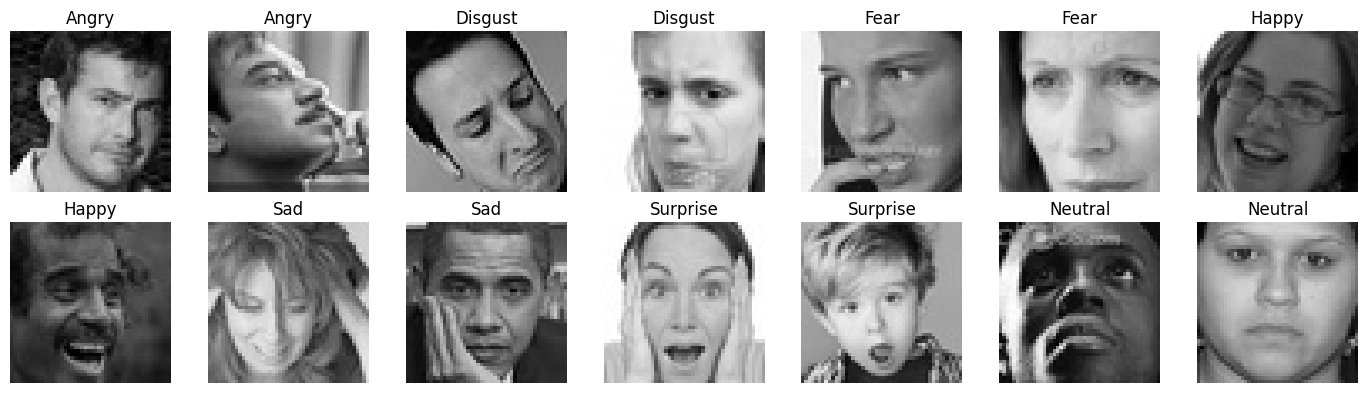

In [ ]:
from IPython.display import display, Markdown

count_lines = [
    "| Split | Total | " + " | ".join(label.capitalize() for label in LABELS) + " |",
    "|---|" + "---:|" * (len(LABELS) + 1),
]
for split_name in ("train", "validation", "test", "excluded"):
    values = manifest["counts"][split_name]["classes"]
    count_lines.append(
        f"| {split_name.capitalize()} | {manifest['counts'][split_name]['records']:,} | "
        + " | ".join(f"{values[label]:,}" for label in LABELS)
        + " |"
    )
display(Markdown("\n".join(count_lines)))

sample_rows = []
for label in LABELS:
    candidates = [
        row for row in manifest["records"]
        if row["split"] == "train" and row["label"] == label
    ]
    sample_rows.extend(candidates[:2])

fig, axes = plt.subplots(2, 7, figsize=(14, 4))
for axis, row in zip(axes.flat, sample_rows):
    with Image.open(TRAIN_DIR / row["relative_path"]) as image:
        shown = image.convert("L").resize(IMAGE_SIZE, Image.Resampling.BILINEAR)
    axis.imshow(shown, cmap="gray", vmin=0, vmax=255)
    axis.set_title(row["label"].capitalize())
    axis.axis("off")
for axis in axes.flat[len(sample_rows):]:
    axis.axis("off")
fig.tight_layout()
plt.show()

## Original MLP Cross-Entropy result (preserved reference)

Copied from the team's completed original baseline run (seed 42). Retained for comparison; not a new run. The fresh Cross-Entropy rerun below is the paired control for the focal-loss runs.

| Metric | Original MLP / Cross-Entropy |
|---|---:|
| Validation accuracy | 36.37% |
| Validation macro-F1 | 0.2700 |
| Best epoch | 8 (11 epochs completed) |
| Training time | 290.7 seconds |
| Per-class F1 — angry | 0.148 |
| Per-class F1 — disgust | 0.000 |
| Per-class F1 — fear | 0.111 |
| Per-class F1 — happy | 0.542 |
| Per-class F1 — sad | 0.319 |
| Per-class F1 — surprise | 0.415 |
| Per-class F1 — neutral | 0.355 |

**Original settings:** Adam, learning rate 0.001, batch size 64, maximum 20 epochs, patience 3, seed 42, no augmentation, no dropout. 295,943 parameters.


## MLP model

Only the assigned MLP is included. Its definition is copied unchanged from the team's baseline notebook. It returns seven raw logits; Cross-Entropy and Focal Loss both consume logits and integer labels.


In [ ]:
class MLP(nn.Module):
    def __init__(self, num_classes=7):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Flatten(),  # [batch, 1, 48, 48] becomes [batch, 2304].
            nn.Linear(48 * 48, 128),  # All pixels feed the 128 hidden units.
            nn.ReLU(),
            nn.Linear(128, num_classes),
        )

    def forward(self, values):
        return self.layers(values)


def make_model(model_id, config):
    if model_id != "mlp":
        raise ValueError("This notebook is scoped to the MLP only.")
    return MLP(num_classes=len(LABELS))


def trainable_parameter_count(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

model = make_model("mlp", {})
model.eval()
with torch.inference_mode():
    shape_check = model(torch.zeros(2, 1, 48, 48))
assert tuple(shape_check.shape) == (2, 7)
print("MLP output shape:", tuple(shape_check.shape))
print("Trainable parameters:", f"{trainable_parameter_count(model):,}")
assert trainable_parameter_count(model) == 295943, "Expected 295,943 parameters (original baseline)."
del model


MLP output shape: (2, 7)
Trainable parameters: 295,943


## Focal loss and training/evaluation functions

Focal Loss is implemented as \(FL(p_t) = -(1-p_t)^\gamma \log(p_t)\). At gamma = 0 it reduces to ordinary cross-entropy. No class weighting is applied (all class weights are effectively 1), so the experiment isolates gamma.

Validation loss is reported as ordinary cross-entropy for every run, making that loss metric comparable across the different training objectives. Accuracy, macro-F1 and per-class F1 are calculated from validation predictions.


In [ ]:
import copy
import csv
import math
import statistics

# Measurement constants; these do not change training.
TRAIN_DIAGNOSTIC_MAX_RECORDS = 512
BENCHMARK_WARMUP = 5
BENCHMARK_REPEATS = 30
BENCHMARK_BATCH_SIZE = 64

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    if hasattr(torch.backends, "cudnn"):
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

def sync_device(device):
    if device.type == "cuda":
        torch.cuda.synchronize(device)
    elif device.type == "mps":
        torch.mps.synchronize()

def write_json(path, payload):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(payload, indent=2, sort_keys=True) + "\n", encoding="utf-8")

def write_csv(path, rows, fields=None):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    fields = fields or (list(rows[0]) if rows else [])
    with path.open("w", newline="", encoding="utf-8") as handle:
        writer = csv.DictWriter(handle, fieldnames=fields)
        writer.writeheader()
        writer.writerows(rows)

def rows_fingerprint(rows):
    values = [(r["source_split"], r["relative_path"], r["class_id"], r.get("image_sha256"), r["split"])
              for r in sorted(rows, key=lambda r: (r["source_split"], r["relative_path"].casefold()))]
    return hashlib.sha256(json.dumps(values, separators=(",", ":")).encode()).hexdigest()

class ManifestDataset(Dataset):
    def __init__(self, rows, profile="gray48", flip_probability=0.0):
        self.rows = rows
        self.profile = profile
        self.flip_probability = flip_probability
        self.roots = {"train": TRAIN_DIR, "test": TEST_DIR}
        if profile != "gray48":
            raise ValueError("This comparison uses grayscale 48x48 images.")

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows[index]
        with Image.open(self.roots[row["source_split"]] / row["relative_path"]) as source:
            image = source.convert("L")
            if self.flip_probability and torch.rand(()).item() < self.flip_probability:
                image = image.transpose(Image.Transpose.FLIP_LEFT_RIGHT)
            image = image.resize(IMAGE_SIZE, Image.Resampling.BILINEAR)
            pixels = np.asarray(image, dtype=np.uint8).copy()
            values = torch.from_numpy(pixels.astype(np.float32) / 255.0).unsqueeze(0)
        return values, int(row["class_id"])

def make_loader(rows, config, training=False):
    return DataLoader(
        ManifestDataset(rows, config.get("input_profile", "gray48"),
                        config.get("flip_probability", 0.0) if training else 0.0),
        batch_size=config["batch_size"], shuffle=training, num_workers=0,
        generator=torch.Generator().manual_seed(config["seed"]),
        pin_memory=(DEVICE.type == "cuda"),
    )

def choose_rows(rows, maximum, seed):
    if maximum is None or len(rows) <= maximum:
        return list(rows)
    class_groups = {
        class_id: [row for row in rows if row["class_id"] == class_id]
        for class_id in range(len(LABELS))
    }
    present = [class_id for class_id, group in class_groups.items() if group]
    if maximum < len(present):
        raise ValueError("The record limit must include at least one row from each present class.")
    exact = {
        class_id: maximum * len(class_groups[class_id]) / len(rows)
        for class_id in present
    }
    quotas = {
        class_id: min(len(class_groups[class_id]), max(1, int(math.floor(exact[class_id]))))
        for class_id in present
    }
    while sum(quotas.values()) > maximum:
        candidates = [class_id for class_id in present if quotas[class_id] > 1]
        class_id = max(candidates, key=lambda key: quotas[key] - exact[key])
        quotas[class_id] -= 1
    while sum(quotas.values()) < maximum:
        candidates = [class_id for class_id in present if quotas[class_id] < len(class_groups[class_id])]
        class_id = max(candidates, key=lambda key: exact[key] - quotas[key])
        quotas[class_id] += 1
    selected = []
    for class_id in present:
        group = list(class_groups[class_id])
        rng = np.random.default_rng(np.random.SeedSequence([seed, class_id, maximum]))
        order = rng.permutation(len(group))
        selected.extend(group[index] for index in order[:quotas[class_id]])
    return sorted(selected, key=lambda row: (row["source_split"], row["relative_path"].casefold()))

def metric_report(y_true, y_pred):
    matrix = np.zeros((len(LABELS), len(LABELS)), dtype=np.int64)
    for truth, prediction in zip(y_true, y_pred):
        matrix[int(truth), int(prediction)] += 1
    per_class = []
    f1_values = []
    for class_id, label in enumerate(LABELS):
        true_positive = int(matrix[class_id, class_id])
        actual = int(matrix[class_id, :].sum())
        predicted = int(matrix[:, class_id].sum())
        precision = true_positive / predicted if predicted else 0.0
        recall = true_positive / actual if actual else 0.0
        f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
        f1_values.append(f1)
        per_class.append({
            "label": label,
            "support": actual,
            "predicted_count": predicted,
            "precision": precision,
            "recall": recall,
            "f1": f1,
        })
    total = int(matrix.sum())
    accuracy = float(np.trace(matrix) / total) if total else 0.0
    return {
        "accuracy": accuracy,
        "macro_f1": float(np.mean(f1_values)),
        "per_class": per_class,
        "confusion_matrix": matrix.tolist(),
    }

class FocalLoss(nn.Module):
    """Multiclass focal loss for raw logits; class weights default to one."""
    def __init__(self, gamma=2.0, class_weights=None, reduction="mean"):
        super().__init__()
        if gamma < 0:
            raise ValueError("gamma must be non-negative")
        self.gamma = float(gamma)
        self.register_buffer("class_weights", class_weights if class_weights is not None else None)
        self.reduction = reduction

    def forward(self, logits, targets):
        ce = nn.functional.cross_entropy(
            logits, targets, weight=self.class_weights, reduction="none"
        )
        p_t = torch.exp(-ce)
        loss = ((1.0 - p_t) ** self.gamma) * ce
        if self.reduction == "mean":
            return loss.mean()
        if self.reduction == "sum":
            return loss.sum()
        if self.reduction == "none":
            return loss
        raise ValueError("reduction must be 'mean', 'sum' or 'none'")


def make_training_loss(config):
    if config["loss_name"] == "cross_entropy":
        return nn.CrossEntropyLoss()
    if config["loss_name"] == "focal_loss":
        return FocalLoss(gamma=config["gamma"])
    raise ValueError(f"Unknown loss: {config['loss_name']}")

# Sanity check: gamma=0 with unit class weights must equal cross-entropy.
_test_logits = torch.tensor([[1.2, -0.3, 0.7], [-0.2, 0.4, 1.1]], dtype=torch.float32)
_test_targets = torch.tensor([0, 2], dtype=torch.long)
_ce_check = nn.CrossEntropyLoss()(_test_logits, _test_targets)
_fl0_check = FocalLoss(gamma=0.0)(_test_logits, _test_targets)
assert torch.allclose(_ce_check, _fl0_check, atol=1e-7), "Focal gamma=0 must match CE."
_g = torch.Generator().manual_seed(0)
_big_logits = torch.randn(256, len(LABELS), generator=_g) * 3
_big_targets = torch.randint(0, len(LABELS), (256,), generator=_g)
assert torch.allclose(nn.CrossEntropyLoss()(_big_logits, _big_targets),
                      FocalLoss(gamma=0.0)(_big_logits, _big_targets), atol=1e-6), "7-class gamma=0 check failed."
# Focal loss must never exceed CE for gamma > 0 (the (1-p_t)^gamma factor is <= 1).
assert FocalLoss(gamma=2.0)(_big_logits, _big_targets) <= nn.CrossEntropyLoss()(_big_logits, _big_targets)
# Extra check: gamma=0 focal loss must also give the same gradients as cross-entropy.
_gl = _big_logits.clone().requires_grad_(True)
nn.CrossEntropyLoss()(_gl, _big_targets).backward()
_grad_ce = _gl.grad.clone()
_gl.grad = None
FocalLoss(gamma=0.0)(_gl, _big_targets).backward()
assert torch.allclose(_grad_ce, _gl.grad, atol=1e-6), "gamma=0 gradient check failed."
print("Focal-loss gamma=0 check passed; CE and focal loss are equal (3-class and 7-class loss values, and gradients).")

@torch.inference_mode()
def evaluate_model(model, loader, include_predictions=False):
    model.eval()  # Disable dropout; do not update weights during scoring.
    criterion = nn.CrossEntropyLoss()
    loss_sum, count = 0.0, 0
    truth, predictions = [], []
    for images, labels in loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        logits = model(images)
        loss_sum += criterion(logits, labels).item() * labels.size(0)
        count += labels.size(0)
        truth.extend(labels.cpu().tolist())
        predictions.extend(logits.argmax(1).cpu().tolist())
    if not count:
        raise ValueError("Cannot score an empty data split.")
    report = metric_report(truth, predictions)
    report["loss"] = loss_sum / count
    if include_predictions:
        report["predictions"] = predictions
    return report

def benchmark_model(model, profile):
    model.eval()
    shape = (1, 48, 48) if profile == "gray48" else (3, 224, 224)
    sizes = sorted({1, BENCHMARK_BATCH_SIZE})
    reports = {}
    with torch.inference_mode():
        for size in sizes:
            values = torch.zeros(size, *shape, device=DEVICE)
            for _ in range(BENCHMARK_WARMUP):
                model(values)
            sync_device(DEVICE)
            samples = []
            for _ in range(BENCHMARK_REPEATS):
                sync_device(DEVICE)
                start = time.perf_counter()
                model(values)
                sync_device(DEVICE)
                samples.append(time.perf_counter() - start)
            median = statistics.median(samples)
            reports[size] = {"median_seconds": median, "p95_seconds": float(np.percentile(samples, 95))}
    return {
        "latency_ms_batch1": reports[1]["median_seconds"] * 1000,
        "latency_p95_ms_batch1": reports[1]["p95_seconds"] * 1000,
        "throughput_images_per_second": BENCHMARK_BATCH_SIZE / reports[BENCHMARK_BATCH_SIZE]["median_seconds"],
        "batch_size": BENCHMARK_BATCH_SIZE, "warmup": BENCHMARK_WARMUP,
        "repeats": BENCHMARK_REPEATS, "device": str(DEVICE),
        "input_shape": list(shape), "torch_threads": torch.get_num_threads(),
        "scope": "model forward only; tensors already on device; synchronized wall time",
    }

def variant_config(loss_name, gamma, seed):
    if loss_name not in {"cross_entropy", "focal_loss"}:
        raise ValueError("Unsupported training loss.")
    if loss_name == "cross_entropy" and gamma != 0:
        raise ValueError("Cross-Entropy uses gamma=0 only as a bookkeeping value.")
    return {
        "model_id": "mlp", "variant": loss_name if loss_name == "cross_entropy" else f"focal_gamma_{gamma}",
        "loss_name": loss_name, "gamma": float(gamma), "seed": seed,
        "optimizer": OPTIMIZER_NAME, "learning_rate": LEARNING_RATE,
        "momentum": MOMENTUM, "weight_decay": WEIGHT_DECAY,
        "batch_size": BATCH_SIZE, "max_epochs": MAX_EPOCHS, "patience": PATIENCE,
        "dropout": 0.0, "flip_probability": 0.0,
        "input_profile": "gray48", "initialization": "fresh_random_weights", "freeze_backbone": False,
    }

def train_one_model(config, study_directory):
    set_seed(config["seed"])  # Fresh model; no baseline checkpoint is reused.
    model = make_model(config["model_id"], config).to(DEVICE)
    loaders = {
        "train": make_loader(train_rows, config, training=True),
        "diagnostic": make_loader(diagnostic_rows, config),
        "validation": make_loader(validation_rows, config),
    }
    parameters = [p for p in model.parameters() if p.requires_grad]
    if config["optimizer"] == "Adam":
        optimizer = torch.optim.Adam(parameters, lr=config["learning_rate"], weight_decay=config["weight_decay"])
    else:
        optimizer = torch.optim.SGD(parameters, lr=config["learning_rate"],
                                    momentum=config["momentum"], weight_decay=config["weight_decay"])
    run_key = f"{config['model_id']}__{config['variant']}__seed{config['seed']}"
    folder = study_directory / "models" / run_key
    folder.mkdir(parents=True, exist_ok=False)
    write_json(folder / "config.json", config)
    (folder / "architecture.txt").write_text(str(model) + "\n")
    criterion = make_training_loss(config)  # Fresh objective for this run.
    best_score, best_loss = -1.0, float("inf")
    best_epoch, stale = 0, 0
    history, best_state = [], None
    stop_reason = "epoch budget reached"
    sync_device(DEVICE)
    started = time.perf_counter()
    for epoch in range(1, config["max_epochs"] + 1):
        epoch_start = time.perf_counter()
        model.train()  # Enable the paper model's dropout for weight updates.
        optimization_loss, count = 0.0, 0
        for images, labels in loaders["train"]:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)  # Clear the previous batch gradients.
            logits = model(images)  # One row of seven raw emotion scores per image.
            loss = criterion(logits, labels)
            if not torch.isfinite(loss):
                raise ValueError("Loss became non-finite. Check the learning rate and inputs.")
            loss.backward()  # Backpropagation calculates a gradient for each learned weight.
            optimizer.step()  # Adam or SGD updates weights using those gradients.
            optimization_loss += loss.item() * labels.size(0)
            count += labels.size(0)
        diagnostic = evaluate_model(model, loaders["diagnostic"])
        validation = evaluate_model(model, loaders["validation"])
        sync_device(DEVICE)
        history.append({
            "epoch": epoch, "optimization_loss": optimization_loss / count,
            "train_loss": diagnostic["loss"], "train_accuracy": diagnostic["accuracy"],
            "validation_loss": validation["loss"], "validation_accuracy": validation["accuracy"],
            "validation_macro_f1": validation["macro_f1"],
            "epoch_seconds": time.perf_counter() - epoch_start,
        })
        # Validation selects a checkpoint; test data never enter this decision.
        score, value = validation["macro_f1"], validation["loss"]
        if score > best_score or (score == best_score and value < best_loss):
            best_score, best_loss, best_epoch = score, value, epoch
            best_state = {key: tensor.detach().cpu().clone() for key, tensor in model.state_dict().items()}
            stale = 0
        else:
            stale += 1
        write_csv(folder / "training_history.csv", history)
        print(f"{run_key} epoch {epoch}: val accuracy {validation['accuracy']:.2%}, "
              f"macro-F1 {score:.4f}, loss {value:.4f}")
        # Stop after the allowed consecutive epochs without a better checkpoint.
        if stale >= config["patience"]:
            stop_reason = "patience reached"
            break
    sync_device(DEVICE)
    training_seconds = time.perf_counter() - started
    if best_state is None:
        raise RuntimeError("No checkpoint was produced.")
    checkpoint = folder / "best_checkpoint.pt"
    torch.save({"model_state_dict": best_state, "config": config, "label_order": list(LABELS),
                "preprocessing": PREPROCESSING if config["input_profile"] == "gray48" else {"profile": "ImageNet RGB224 V1 transforms"},
                "data_fingerprint": DATA_FINGERPRINT, "split_fingerprint": SPLIT_ASSIGNMENT_FINGERPRINT,
                "best_epoch": best_epoch, "validation_macro_f1": best_score}, checkpoint)
    saved = torch.load(checkpoint, map_location="cpu", weights_only=True)
    model.load_state_dict(saved["model_state_dict"])  # Restore the selected epoch, not the last epoch.
    validation = evaluate_model(model, loaders["validation"], include_predictions=True)
    diagnostic = evaluate_model(model, loaders["diagnostic"])
    prediction_values = validation.pop("predictions")
    assert abs(validation["macro_f1"] - best_score) < 1e-10
    speed = benchmark_model(model, config["input_profile"])
    report = {
        "run_key": run_key, "config": config, "history": history, "validation": validation,
        "diagnostic": diagnostic, "gap_percentage_points": 100 * (diagnostic["accuracy"] - validation["accuracy"]),
        "parameters": sum(p.numel() for p in model.parameters()),
        "trainable_parameters": trainable_parameter_count(model),
        "best_epoch": best_epoch, "epochs_completed": len(history), "stop_reason": stop_reason,
        "training_seconds": training_seconds, "mean_epoch_seconds": statistics.mean(r["epoch_seconds"] for r in history),
        "speed": speed, "checkpoint_relative_path": checkpoint.relative_to(study_directory).as_posix(),
        "source_test_evaluated": False,
    }
    write_json(folder / "metrics.json", report)
    write_csv(folder / "per_class_validation.csv", validation["per_class"])
    write_csv(folder / "validation_predictions.csv", [
        {"relative_path": row["relative_path"], "actual": row["label"], "predicted": LABELS[prediction]}
        for row, prediction in zip(validation_rows, prediction_values)
    ])
    del model, optimizer
    return report


Focal-loss gamma=0 check passed; CE and focal loss are equal (3-class and 7-class loss values, and gradients).


In [ ]:
# Four runs: paired CE control, then focal gamma 1, 2 and 4.
# Every call creates a new model after resetting the same seed, so each loss starts from fresh weights.
TRAINING_SEEDS = [SEED]
EXPERIMENTS = [
    ("cross_entropy", 0.0),
    ("focal_loss", 1.0),
    ("focal_loss", 2.0),
    ("focal_loss", 4.0),
]

eligible_train_rows = [r for r in manifest["records"] if r["split"] == "train"]
eligible_validation_rows = [r for r in manifest["records"] if r["split"] == "validation"]
train_rows = list(eligible_train_rows)
validation_rows = list(eligible_validation_rows)
diagnostic_rows = choose_rows(train_rows, TRAIN_DIAGNOSTIC_MAX_RECORDS, SEED + 3)
if not train_rows or not validation_rows:
    raise ValueError("Training and validation splits must not be empty.")
TRAIN_SUBSET_FINGERPRINT = rows_fingerprint(train_rows)
VALIDATION_SUBSET_FINGERPRINT = rows_fingerprint(validation_rows)
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "_" + uuid.uuid4().hex[:6]
STUDY_DIRECTORY = OUTPUT_BASE / DATA_FINGERPRINT / "mlp_focal_loss" / RUN_ID
STUDY_DIRECTORY.mkdir(parents=True, exist_ok=False)
STUDY_CONFIG = {
    "run_id": RUN_ID, "experiment_name": EXPERIMENT_NAME,
    "study": "mlp_cross_entropy_vs_focal_loss",
    "training_seed": SEED, "experiments": [{"loss": a, "gamma": b} for a, b in EXPERIMENTS],
    "split_seed": SEED, "validation_fraction": VALIDATION_FRACTION,
    "data_fingerprint": DATA_FINGERPRINT,
    "split_fingerprint": SPLIT_ASSIGNMENT_FINGERPRINT,
    "train_subset_fingerprint": TRAIN_SUBSET_FINGERPRINT,
    "validation_subset_fingerprint": VALIDATION_SUBSET_FINGERPRINT,
    "train_records": len(train_rows), "validation_records": len(validation_rows),
    "source_test_evaluated": False,
}
write_json(STUDY_DIRECTORY / "study_config.json", STUDY_CONFIG)
write_json(STUDY_DIRECTORY / "split_manifest.json", manifest)
write_json(STUDY_DIRECTORY / "selected_rows.json", {"train": train_rows, "validation": validation_rows})

completed_runs = []
for loss_name, gamma in EXPERIMENTS:
    config = variant_config(loss_name, gamma, SEED)
    result = train_one_model(config, STUDY_DIRECTORY)
    completed_runs.append(result)
    write_json(STUDY_DIRECTORY / "completed_runs.json", completed_runs)

print("Study directory:", STUDY_DIRECTORY)
print("Completed experiments:", len(completed_runs))
print("Source test set scored: False")


mlp__cross_entropy__seed42 epoch 1: val accuracy 33.68%, macro-F1 0.1966, loss 1.7069
mlp__cross_entropy__seed42 epoch 2: val accuracy 34.94%, macro-F1 0.2248, loss 1.6830
mlp__cross_entropy__seed42 epoch 3: val accuracy 34.03%, macro-F1 0.2126, loss 1.6759
mlp__cross_entropy__seed42 epoch 4: val accuracy 35.63%, macro-F1 0.2332, loss 1.6438
mlp__cross_entropy__seed42 epoch 5: val accuracy 32.89%, macro-F1 0.2407, loss 1.6818
mlp__cross_entropy__seed42 epoch 6: val accuracy 35.32%, macro-F1 0.2501, loss 1.6389
mlp__cross_entropy__seed42 epoch 7: val accuracy 37.11%, macro-F1 0.2632, loss 1.6185
mlp__cross_entropy__seed42 epoch 8: val accuracy 36.37%, macro-F1 0.2700, loss 1.6359
mlp__cross_entropy__seed42 epoch 9: val accuracy 36.83%, macro-F1 0.2585, loss 1.6158
mlp__cross_entropy__seed42 epoch 10: val accuracy 36.97%, macro-F1 0.2519, loss 1.6062
mlp__cross_entropy__seed42 epoch 11: val accuracy 36.44%, macro-F1 0.2431, loss 1.6185
mlp__focal_gamma_1.0__seed42 epoch 1: val accuracy 3

## Results: accuracy, macro-F1, per-class F1 and training time

This cell creates separate CSV/JSON records for the new experiments. It also prints the preserved original Cross-Entropy result beside the fresh runs. Do not use the held-out source-test split to choose gamma.


In [ ]:
from IPython.display import display, Markdown

def show_table(headers, rows):
    lines = ["| " + " | ".join(headers) + " |", "|" + "|".join(["---"] * len(headers)) + "|"]
    lines += ["| " + " | ".join(str(v) for v in row) + " |" for row in rows]
    display(Markdown("\n".join(lines)))

summary_rows = []
per_class_rows = []
for run in completed_runs:
    cfg, val = run["config"], run["validation"]
    label = "Cross-Entropy (fresh rerun)" if cfg["loss_name"] == "cross_entropy" else f"Focal Loss (gamma={cfg['gamma']:g})"
    summary_rows.append({
        "experiment": label, "loss": cfg["loss_name"], "gamma": cfg["gamma"],
        "accuracy_percent": val["accuracy"] * 100, "macro_f1": val["macro_f1"],
        "training_seconds": run["training_seconds"], "best_epoch": run["best_epoch"],
        "epochs_completed": run["epochs_completed"], "device": DEVICE.type,
    })
    for metric in val["per_class"]:
        per_class_rows.append({"experiment": label, "gamma": cfg["gamma"], **metric})

write_csv(STUDY_DIRECTORY / "mlp_focal_loss_comparison.csv", summary_rows)
write_csv(STUDY_DIRECTORY / "mlp_focal_loss_per_class_f1.csv", per_class_rows)
write_json(STUDY_DIRECTORY / "mlp_focal_loss_results.json", {
    "original_cross_entropy_reference": {
        "accuracy_percent": 36.37, "macro_f1": 0.2700, "training_seconds": 290.7,
        "best_epoch": 8, "epochs_completed": 11,
        "per_class_f1": {"angry": 0.148, "disgust": 0.000, "fear": 0.111,
                         "happy": 0.542, "sad": 0.319, "surprise": 0.415, "neutral": 0.355},
        "source": "team baseline notebook's saved MLP Cross-Entropy result; historical reference, not rerun",
    },
    "new_runs": summary_rows, "per_class": per_class_rows,
    "split_fingerprint": SPLIT_ASSIGNMENT_FINGERPRINT,
    "source_test_evaluated": False,
})

show_table(["Experiment", "Accuracy (%)", "Macro-F1", "Training time (s)", "Best epoch", "Epochs run", "Device"], [
    ["Original CE reference", "36.37", "0.2700", "290.7", 8, 11, "not recorded"],
    *[[r["experiment"], f"{r['accuracy_percent']:.2f}", f"{r['macro_f1']:.4f}",
       f"{r['training_seconds']:.1f}", r["best_epoch"], r["epochs_completed"], r["device"]] for r in summary_rows]
])
display(Markdown("*Training time depends on the device and on how many epochs early stopping allowed. "
                 "Use it only to compare runs within this notebook, not across notebooks.*"))
show_table(["Experiment", "Emotion", "Support", "F1"], [
    [r["experiment"], r["label"], r["support"], f"{r['f1']:.4f}"] for r in per_class_rows
])
print("Saved results in:", STUDY_DIRECTORY)


| Experiment | Accuracy (%) | Macro-F1 | Training time (s) | Best epoch | Epochs run | Device |
|---|---|---|---|---|---|---|
| Original CE reference | 36.37 | 0.2700 | 290.7 | 8 | 11 | not recorded |
| Cross-Entropy (fresh rerun) | 36.37 | 0.2700 | 592.0 | 8 | 11 | cuda |
| Focal Loss (gamma=1) | 36.92 | 0.2739 | 610.6 | 8 | 11 | cuda |
| Focal Loss (gamma=2) | 36.52 | 0.2753 | 506.7 | 6 | 9 | cuda |
| Focal Loss (gamma=4) | 36.63 | 0.2744 | 636.0 | 8 | 11 | cuda |

*Training time depends on the device and on how many epochs early stopping allowed. Use it only to compare runs within this notebook, not across notebooks.*

| Experiment | Emotion | Support | F1 |
|---|---|---|---|
| Cross-Entropy (fresh rerun) | angry | 580 | 0.1480 |
| Cross-Entropy (fresh rerun) | disgust | 58 | 0.0000 |
| Cross-Entropy (fresh rerun) | fear | 596 | 0.1114 |
| Cross-Entropy (fresh rerun) | happy | 1073 | 0.5417 |
| Cross-Entropy (fresh rerun) | sad | 715 | 0.3192 |
| Cross-Entropy (fresh rerun) | surprise | 432 | 0.4150 |
| Cross-Entropy (fresh rerun) | neutral | 736 | 0.3547 |
| Focal Loss (gamma=1) | angry | 580 | 0.2047 |
| Focal Loss (gamma=1) | disgust | 58 | 0.0000 |
| Focal Loss (gamma=1) | fear | 596 | 0.1315 |
| Focal Loss (gamma=1) | happy | 1073 | 0.5458 |
| Focal Loss (gamma=1) | sad | 715 | 0.2893 |
| Focal Loss (gamma=1) | surprise | 432 | 0.4020 |
| Focal Loss (gamma=1) | neutral | 736 | 0.3440 |
| Focal Loss (gamma=2) | angry | 580 | 0.1503 |
| Focal Loss (gamma=2) | disgust | 58 | 0.0000 |
| Focal Loss (gamma=2) | fear | 596 | 0.1623 |
| Focal Loss (gamma=2) | happy | 1073 | 0.5414 |
| Focal Loss (gamma=2) | sad | 715 | 0.3068 |
| Focal Loss (gamma=2) | surprise | 432 | 0.4154 |
| Focal Loss (gamma=2) | neutral | 736 | 0.3507 |
| Focal Loss (gamma=4) | angry | 580 | 0.2113 |
| Focal Loss (gamma=4) | disgust | 58 | 0.0000 |
| Focal Loss (gamma=4) | fear | 596 | 0.1233 |
| Focal Loss (gamma=4) | happy | 1073 | 0.5437 |
| Focal Loss (gamma=4) | sad | 715 | 0.2752 |
| Focal Loss (gamma=4) | surprise | 432 | 0.4198 |
| Focal Loss (gamma=4) | neutral | 736 | 0.3477 |

Saved results in: /content/fer2013_colab_runs/d67be25b0158b2017c0f4ad4eca68b8632bd9ec66bb579cf2de8224fe1eabf82/mlp_focal_loss/20261110T073109Z_b5c177


## Notes for the report (MLP)

Describe the measured differences; do not assume a larger gamma is better. Focal loss multiplies each example's cross-entropy by (1 − p_t)^gamma, so well-classified examples contribute less and hard examples relatively more. The effect on an MLP may differ from a CNN because the MLP's baseline accuracy is low and many examples are "hard" at the start. Report the measured validation numbers, the single seed, and any unfinished runs. The fresh Cross-Entropy rerun is the controlled comparison; the original row is a historical reference.

**Seed statement:** the MLP gains are small (largest macro-F1 increase 0.0053), and repeatability was not measured because only one seed was used. One seed cannot estimate run-to-run variation, so the notebook makes no claim that the differences are real or due to noise.

**Timing statement:** training times are shown for completeness only. The MLP and Small CNN notebooks ran on different devices, and early stopping changed the number of epochs, so the times must not be used to claim that a model or loss is faster.


## Combined table: MLP and Small CNN, Cross-Entropy vs Focal Loss

The MLP numbers come from the runs above. The Small CNN numbers (corrected Small CNN notebook, run 20261109T235034Z_68aa20) are loaded from its saved CSV files when they are available (upload `focal_loss_comparison.csv` and `focal_loss_per_class_f1.csv` from the Small CNN run folder to `/content`). If the files are not uploaded, the cell falls back to recorded values and prints their exact source. Both models use the same data split and training settings (validation split, seed 42).

**Timing caution:** the two notebooks ran on different devices, and early stopping changed the number of epochs. Training times are listed with a device column for completeness and must not be used to claim that a model or loss is faster.


Small CNN source: recorded values from the Small CNN notebook (run 20261109T235034Z_68aa20); CSV files not found


| Model | Loss | Acc (%) | Macro-F1 | Angry F1 | Disgust F1 | Fear F1 | Happy F1 | Sad F1 | Surprise F1 | Neutral F1 | Train (s) | Best ep. | Epochs run | Device |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| Small CNN | Cross-Entropy (fresh rerun) | 48.81 | 0.392 | 0.375 | 0.0 | 0.214 | 0.711 | 0.37 | 0.596 | 0.478 | 777.3 | 15 | 18 | cpu |
| Small CNN | Focal Loss (gamma=1) | 46.87 | 0.384 | 0.34 | 0.0 | 0.245 | 0.688 | 0.362 | 0.588 | 0.464 | 770.5 | 15 | 18 | cpu |
| Small CNN | Focal Loss (gamma=2) | 46.09 | 0.3733 | 0.344 | 0.0 | 0.25 | 0.688 | 0.331 | 0.54 | 0.46 | 638.8 | 12 | 15 | cpu |
| Small CNN | Focal Loss (gamma=4) | 44.58 | 0.3597 | 0.27 | 0.0 | 0.203 | 0.675 | 0.377 | 0.547 | 0.446 | 473.5 | 8 | 11 | cpu |
| MLP | Cross-Entropy (fresh rerun) | 36.37 | 0.27 | 0.148 | 0.0 | 0.111 | 0.542 | 0.319 | 0.415 | 0.355 | 592.0 | 8 | 11 | cuda |
| MLP | Focal Loss (gamma=1) | 36.92 | 0.2739 | 0.205 | 0.0 | 0.131 | 0.546 | 0.289 | 0.402 | 0.344 | 610.6 | 8 | 11 | cuda |
| MLP | Focal Loss (gamma=2) | 36.52 | 0.2753 | 0.15 | 0.0 | 0.162 | 0.541 | 0.307 | 0.415 | 0.351 | 506.7 | 6 | 9 | cuda |
| MLP | Focal Loss (gamma=4) | 36.63 | 0.2744 | 0.211 | 0.0 | 0.123 | 0.544 | 0.275 | 0.42 | 0.348 | 636.0 | 8 | 11 | cuda |

*The two models ran on different devices and early stopping changed the number of epochs, so training times are not comparable across the two notebooks. Small CNN values: recorded values from the Small CNN notebook (run 20261109T235034Z_68aa20); CSV files not found.*

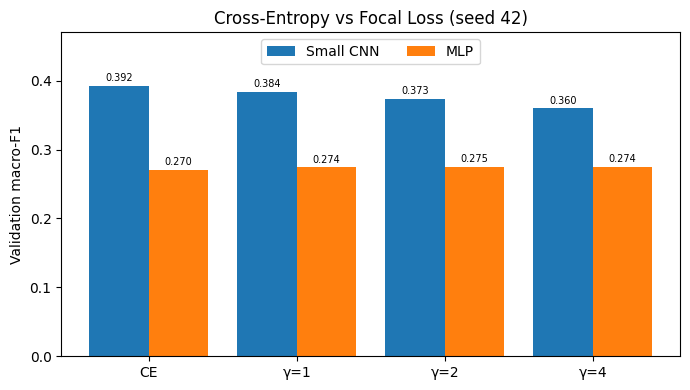

Saved: /content/fer2013_colab_runs/d67be25b0158b2017c0f4ad4eca68b8632bd9ec66bb579cf2de8224fe1eabf82/mlp_focal_loss/20261110T073109Z_b5c177/combined_mlp_cnn_focal_loss_table.csv


In [ ]:
import csv as _csv
from pathlib import Path

# --- Source of the Small CNN values -------------------------------------------------
# Preferred: load the Small CNN notebook's saved CSV files (upload them to /content).
CNN_COMPARISON_CSV = Path("/content/focal_loss_comparison.csv")
CNN_PER_CLASS_CSV = Path("/content/focal_loss_per_class_f1.csv")
CNN_DEVICE = "cpu"  # device reported by the corrected Small CNN notebook's runtime cell (torch 2.14.1+cpu, cuda_available False)

# Fallback (used only if the CSV files are missing): values recorded from the corrected Small CNN notebook,
# run 20261109T235034Z_68aa20, seed 42, validation split. Update this block if that notebook is rerun.
CNN_FALLBACK = {
    "Cross-Entropy (fresh rerun)": dict(acc=48.81, f1=0.3920, sec=777.3, best=15, done=18,
        pc=[0.3751, 0.0000, 0.2139, 0.7107, 0.3700, 0.5963, 0.4777]),
    "Focal Loss (gamma=1)": dict(acc=46.87, f1=0.3840, sec=770.5, best=15, done=18,
        pc=[0.3403, 0.0000, 0.2451, 0.6884, 0.3619, 0.5882, 0.4637]),
    "Focal Loss (gamma=2)": dict(acc=46.09, f1=0.3733, sec=638.8, best=12, done=15,
        pc=[0.3436, 0.0000, 0.2502, 0.6884, 0.3306, 0.5405, 0.4597]),
    "Focal Loss (gamma=4)": dict(acc=44.58, f1=0.3597, sec=473.5, best=8, done=11,
        pc=[0.2702, 0.0000, 0.2027, 0.6754, 0.3770, 0.5466, 0.4459]),
}

def load_cnn_results():
    results = {}
    with open(CNN_COMPARISON_CSV, newline="") as handle:
        for row in _csv.DictReader(handle):
            results[row["experiment"]] = dict(
                acc=float(row["accuracy_percent"]), f1=float(row["macro_f1"]),
                sec=float(row["training_seconds"]), best=int(float(row["best_epoch"])),
                done=int(float(row["epochs_completed"])), pc=[None] * len(LABELS))
    with open(CNN_PER_CLASS_CSV, newline="") as handle:
        for row in _csv.DictReader(handle):
            if row["experiment"] in results:
                results[row["experiment"]]["pc"][LABELS.index(row["label"])] = float(row["f1"])
    for name, value in results.items():
        assert None not in value["pc"], f"Missing per-class F1 for {name}"
    assert len(results) == 4, "Expected 4 Small CNN runs (cross-entropy and gamma 1, 2, 4)."
    return results

if CNN_COMPARISON_CSV.exists() and CNN_PER_CLASS_CSV.exists():
    CNN_RESULTS = load_cnn_results()
    CNN_SOURCE = f"loaded from {CNN_COMPARISON_CSV.name} and {CNN_PER_CLASS_CSV.name}"
else:
    CNN_RESULTS = CNN_FALLBACK
    CNN_SOURCE = "recorded values from the Small CNN notebook (run 20261109T235034Z_68aa20); CSV files not found"
    print("WARNING: Small CNN CSV files not found in /content; using recorded fallback values.")
print("Small CNN source:", CNN_SOURCE)

# --- Combined table ---------------------------------------------------------------
def mlp_per_class(row):
    run = next(x for x in completed_runs
               if x["config"]["loss_name"] == row["loss"] and x["config"]["gamma"] == row["gamma"])
    return [m["f1"] for m in run["validation"]["per_class"]]

combined = []
for model_name, device_name, rows in (
        ("Small CNN", CNN_DEVICE, list(CNN_RESULTS.items())),
        ("MLP", DEVICE.type, [(r["experiment"], dict(acc=r["accuracy_percent"], f1=r["macro_f1"],
                              sec=r["training_seconds"], best=r["best_epoch"], done=r["epochs_completed"],
                              pc=mlp_per_class(r))) for r in summary_rows])):
    for name, v in rows:
        combined.append({"model": model_name, "loss": name, "accuracy_percent": round(v["acc"], 2),
                         "macro_f1": round(v["f1"], 4), **{f"f1_{l}": round(x, 3) for l, x in zip(LABELS, v["pc"])},
                         "training_seconds": round(v["sec"], 1), "best_epoch": v["best"],
                         "epochs_completed": v["done"], "device": device_name})
write_csv(STUDY_DIRECTORY / "combined_mlp_cnn_focal_loss_table.csv", combined)
show_table(["Model", "Loss", "Acc (%)", "Macro-F1", *[l.capitalize() + " F1" for l in LABELS],
            "Train (s)", "Best ep.", "Epochs run", "Device"],
           [[r["model"], r["loss"], r["accuracy_percent"], r["macro_f1"], *[r[f"f1_{l}"] for l in LABELS],
             r["training_seconds"], r["best_epoch"], r["epochs_completed"], r["device"]] for r in combined])
display(Markdown("*The two models ran on different devices and early stopping changed the number of epochs, "
                 "so training times are not comparable across the two notebooks. Small CNN values: " + CNN_SOURCE + ".*"))

# Grouped bar chart: macro-F1 by gamma for both models
fig, axis = plt.subplots(figsize=(7, 4))
gammas = ["CE", "γ=1", "γ=2", "γ=4"]
for k, (m, offset) in enumerate((("Small CNN", -0.2), ("MLP", 0.2))):
    vals = [r["macro_f1"] for r in combined if r["model"] == m]
    bars = axis.bar(np.arange(4) + offset, vals, 0.4, label=m)
    axis.bar_label(bars, fmt="%.3f", fontsize=7, padding=2)
axis.set_xticks(range(4), gammas); axis.set(ylabel="Validation macro-F1", title="Cross-Entropy vs Focal Loss (seed 42)")
axis.set_ylim(0, 0.47); axis.legend(loc="upper center", ncol=2); fig.tight_layout()
fig.savefig(STUDY_DIRECTORY / "combined_macro_f1.png", dpi=180); plt.show()
print("Saved:", STUDY_DIRECTORY / "combined_mlp_cnn_focal_loss_table.csv")


## Export the full MLP experiment folder

Zips the whole study folder (histories, predictions, model weights, metadata, CSV files and figures) and downloads it, so the complete outputs can be handed over. Colab deletes these files when the session ends, so run this cell before closing Colab.


In [ ]:
import shutil

archive_path = shutil.make_archive("/content/mlp_focal_loss_experiment_folder", "zip", str(STUDY_DIRECTORY))
print("Created:", archive_path)
try:
    from google.colab import files
    files.download(archive_path)
except ImportError:
    print("Not running in Colab; copy the zip file manually.")


Created: /content/mlp_focal_loss_experiment_folder.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>